# Hàm sigmoid

*Bài 4, mục 4.1.2.* Hàm sigmoid $\sigma(s) = \dfrac{1}{1 + e^{-s}}$ biến mọi số thực thành một giá trị trong khoảng $(0, 1)$, được dùng để biểu diễn xác suất trong hồi quy Logistic.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def sigmoid(s):
    return 1 / (1 + np.exp(-s))


def sigmoid_derivative(s):
    # sigma'(s) = sigma(s) * (1 - sigma(s))
    return sigmoid(s) * (1 - sigmoid(s))

## 1. Giá trị của sigmoid tại một số điểm

$s$ rất âm cho giá trị gần 0, $s$ rất dương cho giá trị gần 1, $\sigma(0) = 0.5$.

In [2]:
s = np.array([-5, -1, 0, 1, 5])
print('s          :', s)
print('sigmoid(s) :', sigmoid(s).round(4))
print("sigmoid'(s):", sigmoid_derivative(s).round(4))

s          : [-5 -1  0  1  5]
sigmoid(s) : [0.0067 0.2689 0.5    0.7311 0.9933]
sigmoid'(s): [0.0066 0.1966 0.25   0.1966 0.0066]


## 2. Kiểm tra các tính chất

- Đối xứng: $\sigma(-s) = 1 - \sigma(s)$.
- Đạo hàm $\sigma'(s) = \sigma(s)(1 - \sigma(s))$: so sánh với đạo hàm số tính bằng sai phân trung tâm $\dfrac{\sigma(s + \varepsilon) - \sigma(s - \varepsilon)}{2\varepsilon}$.

In [3]:
print('sigma(-s) == 1 - sigma(s):', np.allclose(sigmoid(-s), 1 - sigmoid(s)))

eps = 1e-6
numerical_derivative = (sigmoid(s + eps) - sigmoid(s - eps)) / (2 * eps)
print('Đạo hàm số khớp công thức:', np.allclose(numerical_derivative, sigmoid_derivative(s)))

sigma(-s) == 1 - sigma(s): True
Đạo hàm số khớp công thức: True


## 3. Đồ thị

Đạo hàm đạt cực đại $0.25$ tại $s = 0$ và gần bằng 0 khi $|s|$ lớn.

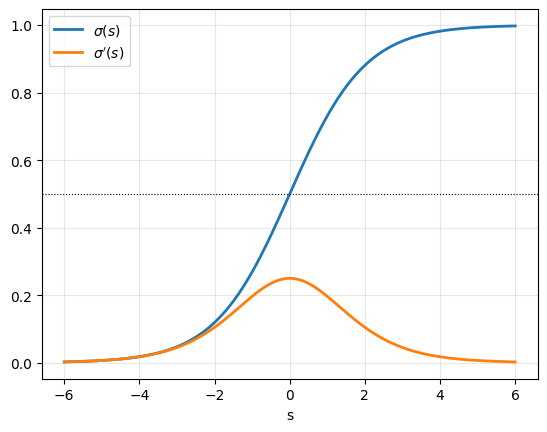

In [4]:
s = np.linspace(-6, 6, 400)
plt.plot(s, sigmoid(s), lw=2, label=r'$\sigma(s)$')
plt.plot(s, sigmoid_derivative(s), lw=2, label=r"$\sigma'(s)$")
plt.axhline(0.5, color='k', ls=':', lw=0.8)
plt.xlabel('s')
plt.legend()
plt.grid(alpha=0.3)
plt.show()